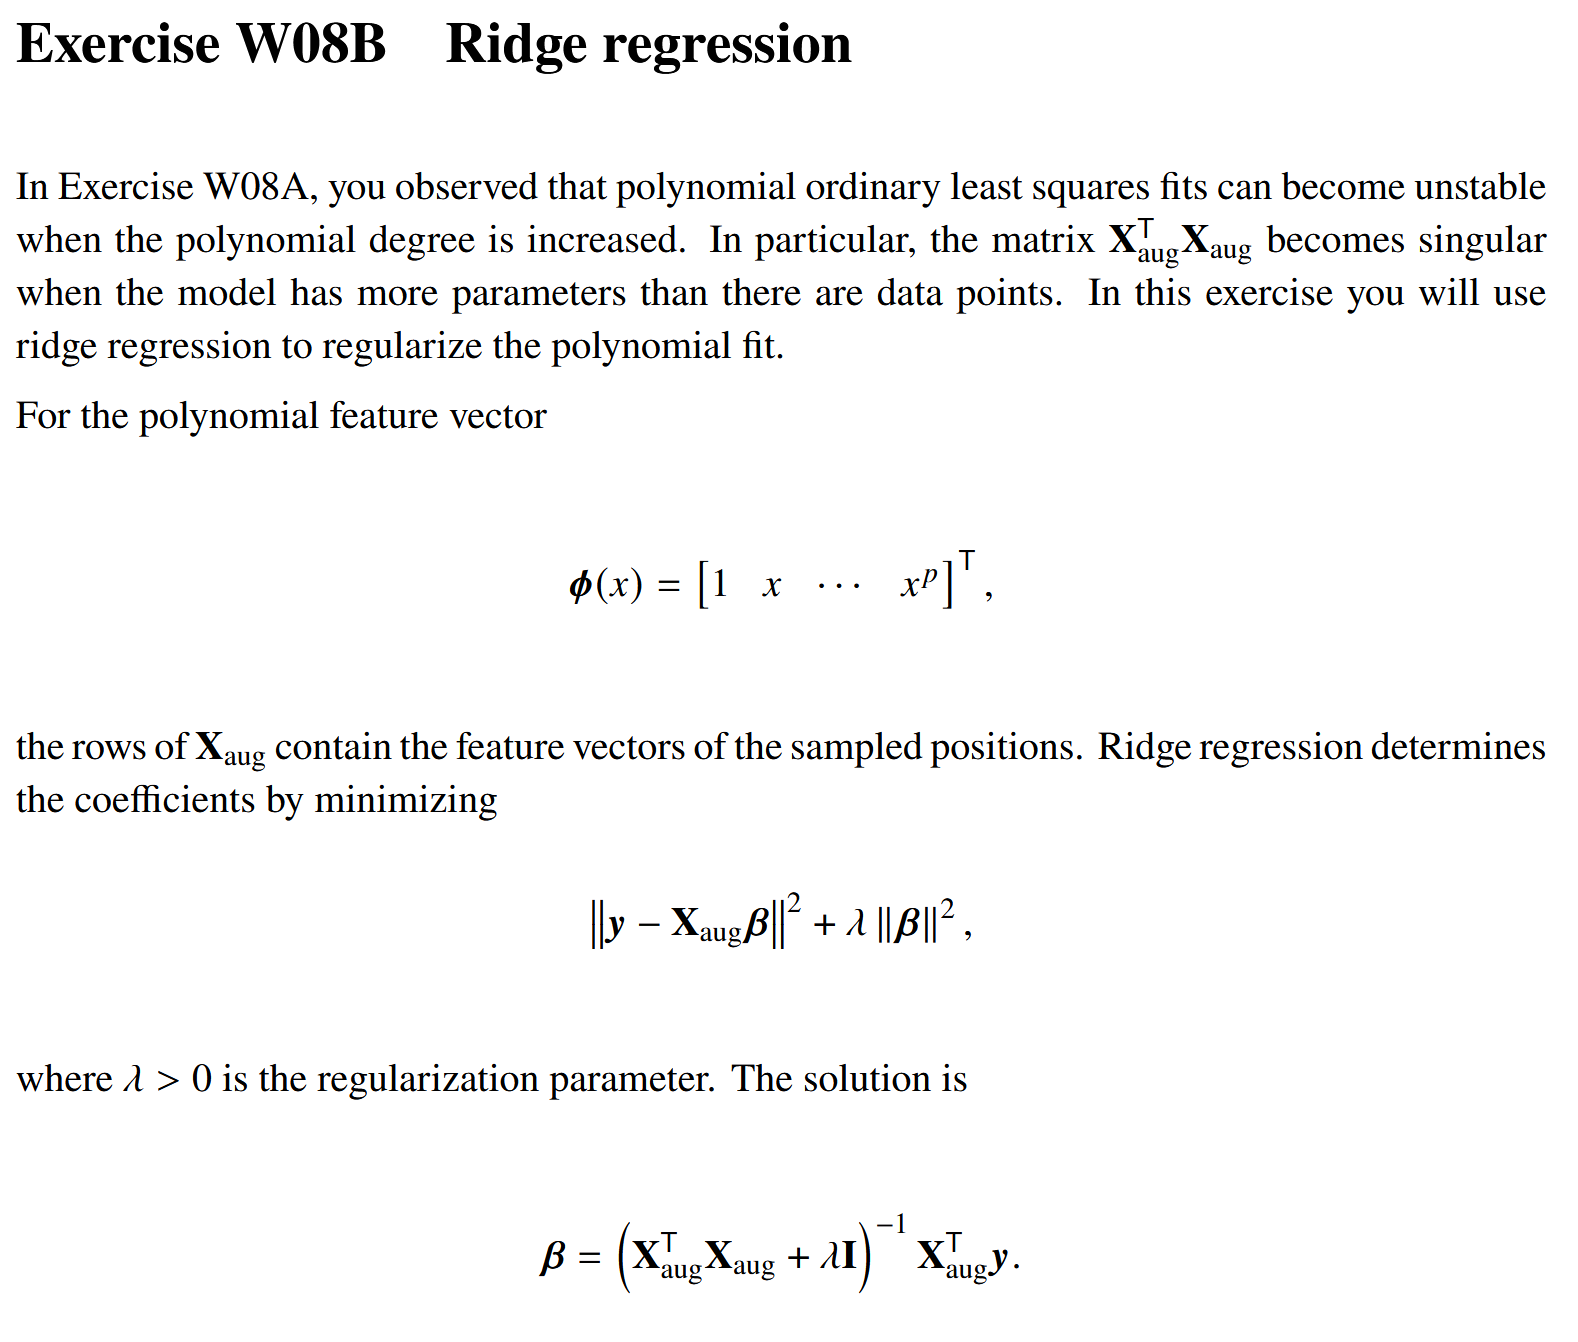
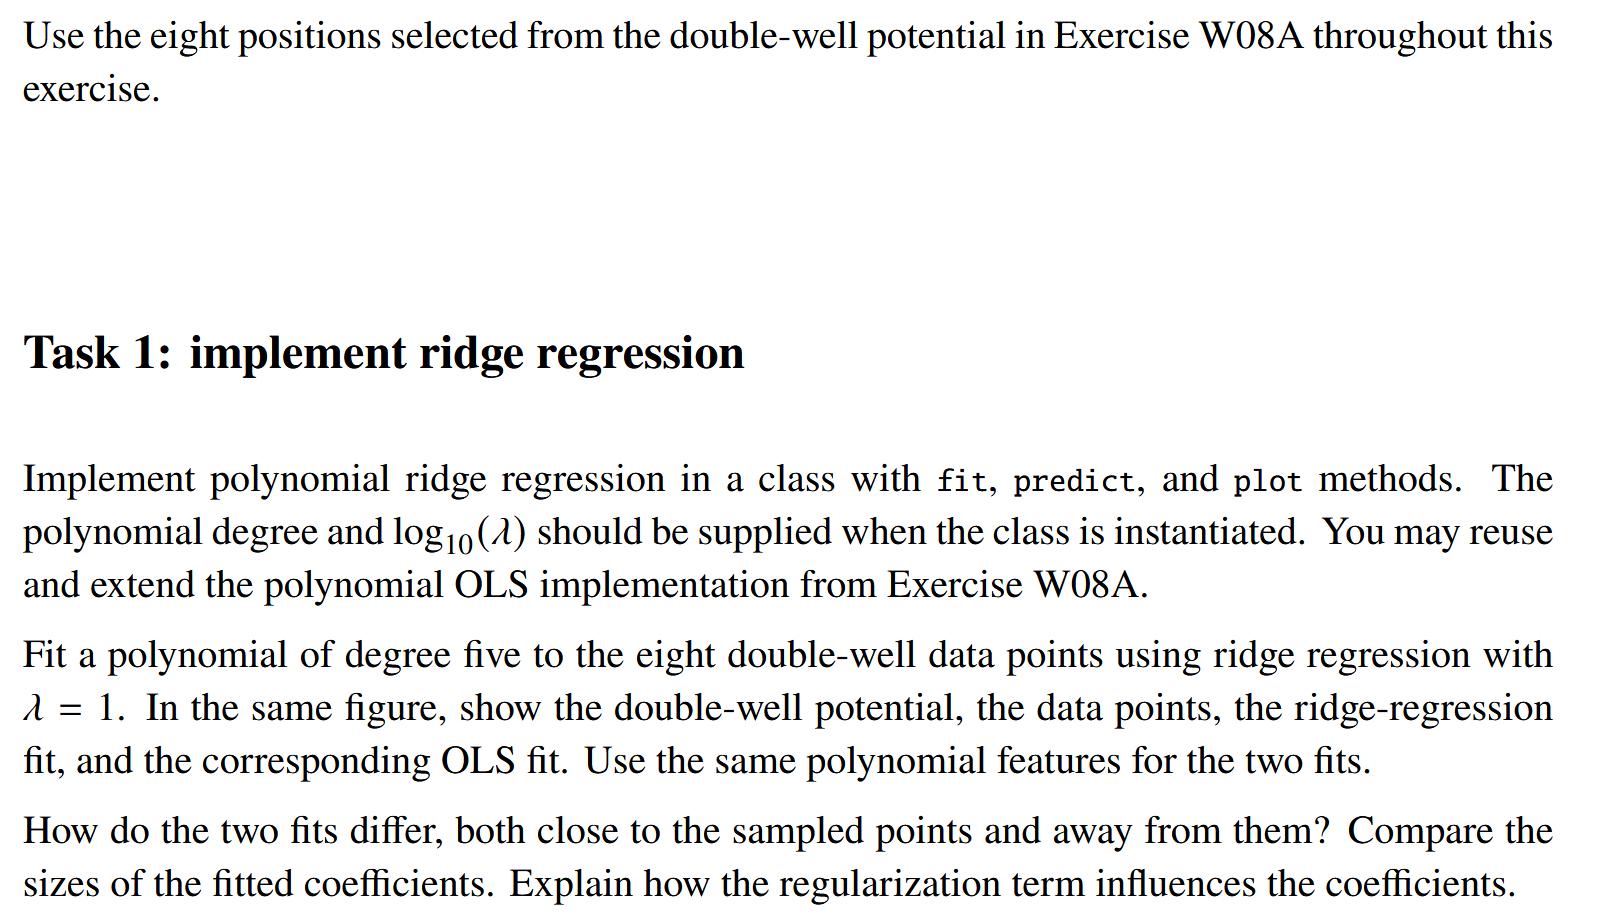

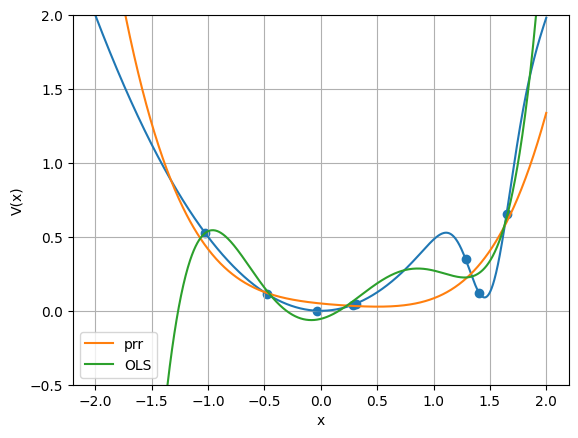

In [ ]:
import numpy as np
import matplotlib.pyplot as plt 
from Metropolis import *
from Regression import * 

points = np.array([-1.02743459, 1.40559573, 1.28419862, 1.6480335, 0.28985161, -0.47948095, 0.31194129, -0.0374767])

class PolyRidgeRegression:
    def __init__(self, Ndegree, lam):
        self.Ndegree = Ndegree
        self.l = lam
        self.beta = None

    def fit(self, X, y):
        X_aug = np.array([[x**p for p in range(self.Ndegree + 1)] for x in X])
        Il = self.l * np.identity(self.Ndegree+1)
        Xs = np.linalg.inv((X_aug.T @ X_aug) + Il) @ X_aug.T
        self.beta = Xs @ y
        return self.beta, X_aug

    def predict(self, X):
        if type(self.beta) == type(None):
            raise ValueError('No β, run .fit() first')
        
        X_aug = np.array([[x**p for p in range(self.Ndegree + 1)] for x in X])

        return X_aug @ self.beta

    def plot(self, ax, X): 
        y = self.predict(X)
        ax.scatter(X, y)

potential = DoubleWell()

prr = PolyRidgeRegression(5, 1)
prr.fit(points, potential.V(points))

fig, ax = plt.subplots(1, 1)
x_lin = np.linspace(-2, 2, 1000)
ax.plot(x_lin, potential.V(x_lin))
ax.scatter(points, potential.V(points))
ols = OLFitPoly(5)
ols.fit(points, potential.V(points))

ax.plot(x_lin, prr.predict(x_lin), label='prr')
ax.plot(x_lin, ols.predict(x_lin), label='OLS')

ax.grid()
ax.set_xlabel('x')
ax.set_ylabel('V(x)')
ax.set_ylim(-0.5, 2.0)
ax.legend()



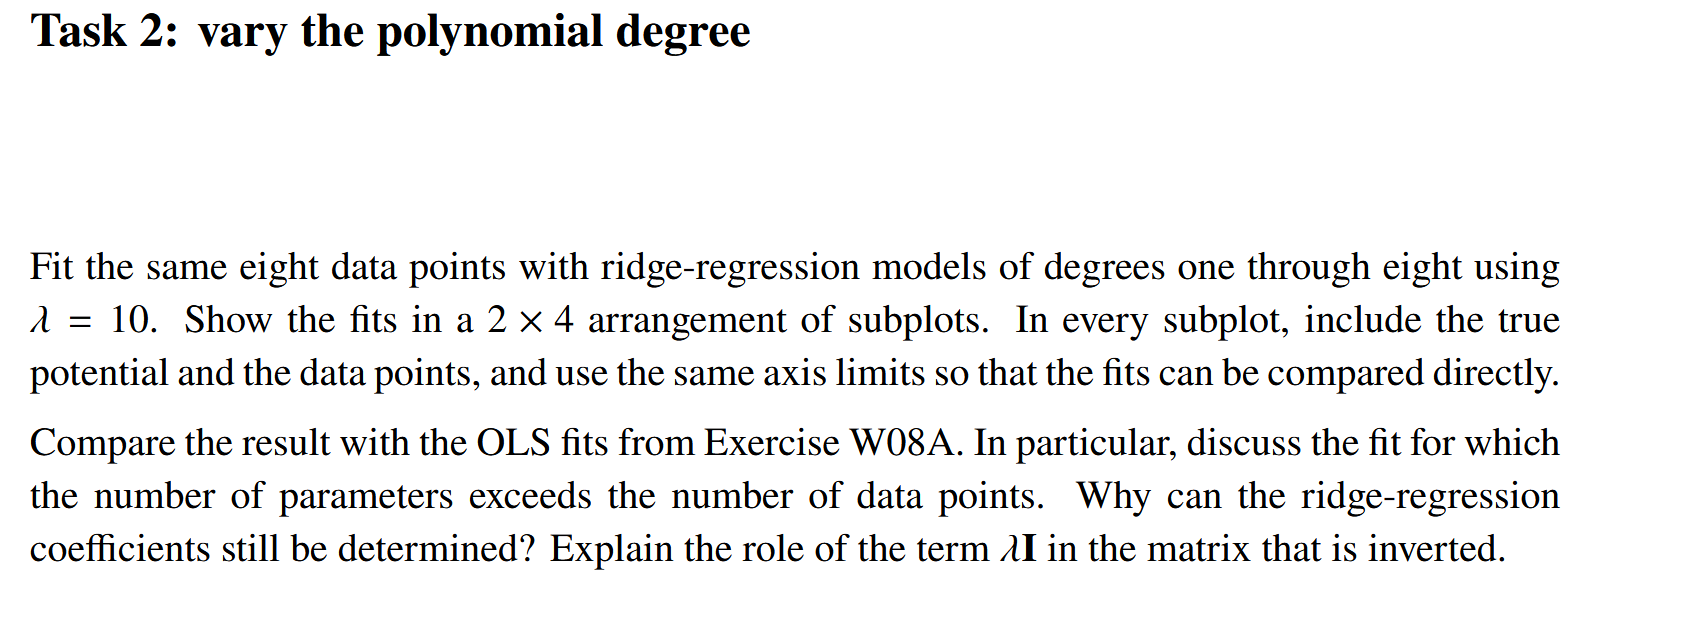

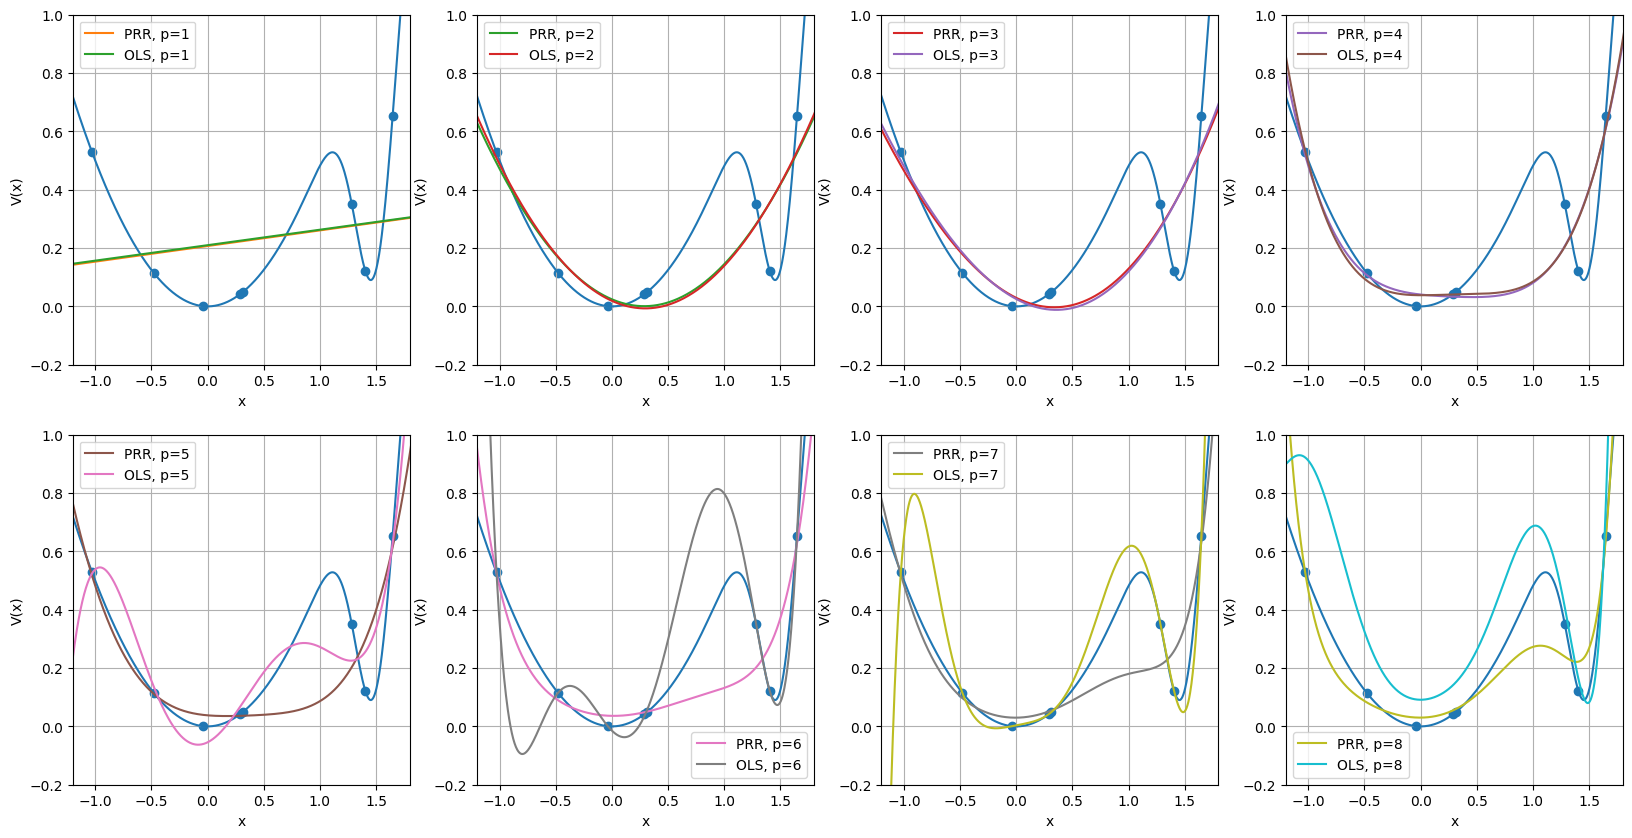

In [43]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, ax in enumerate(axes):
    prr = PolyRidgeRegression(i+1, 0.1)
    prr.fit(points, potential.V(points))

    ols = OLFitPoly(i+1)
    ols.fit(points, potential.V(points))

    ax.plot(x_lin, potential.V(x_lin))
    ax.scatter(points, potential.V(points))

    ax.plot(x_lin, prr.predict(x_lin), label=f'PRR, p={i+1}', color=f'C{i+1}')
    ax.plot(x_lin, ols.predict(x_lin), label=f'OLS, p={i+1}', color=f'C{i+2}')
    ax.grid()
    ax.set_xlabel('x')
    ax.set_ylabel('V(x)')

    ax.set_xlim(-1.2, 1.8)
    ax.set_ylim(-0.2, 1.0)
    ax.legend()

fig.savefig('w08b_p8')

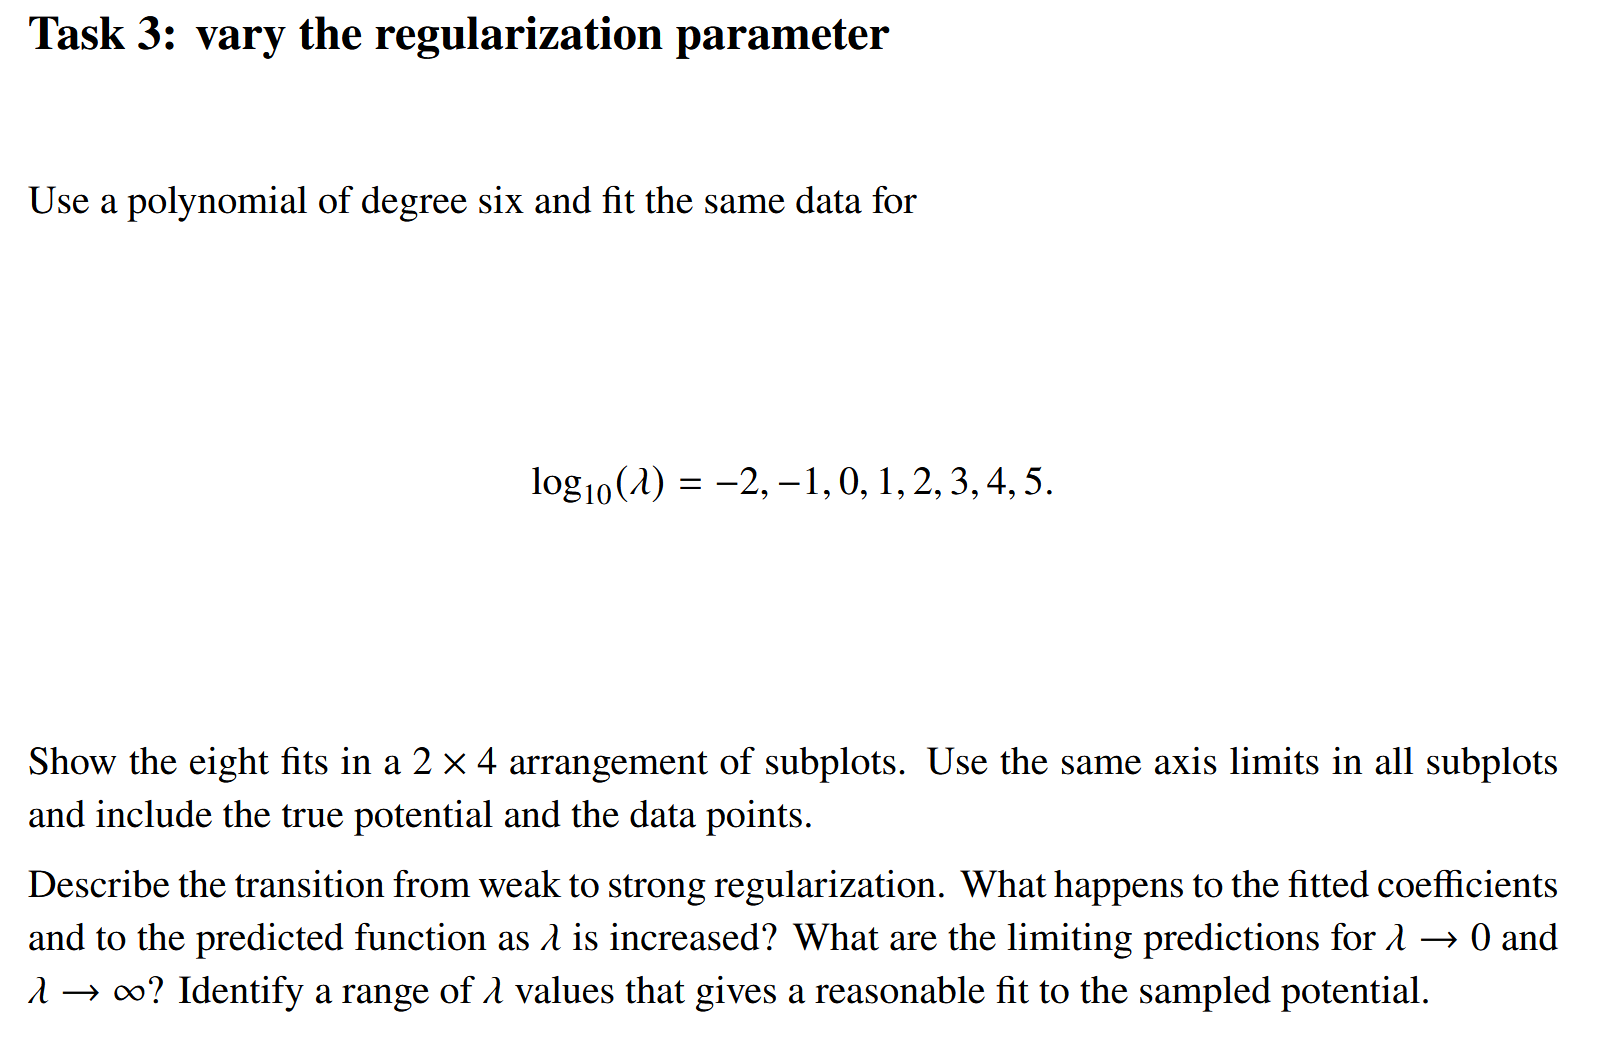

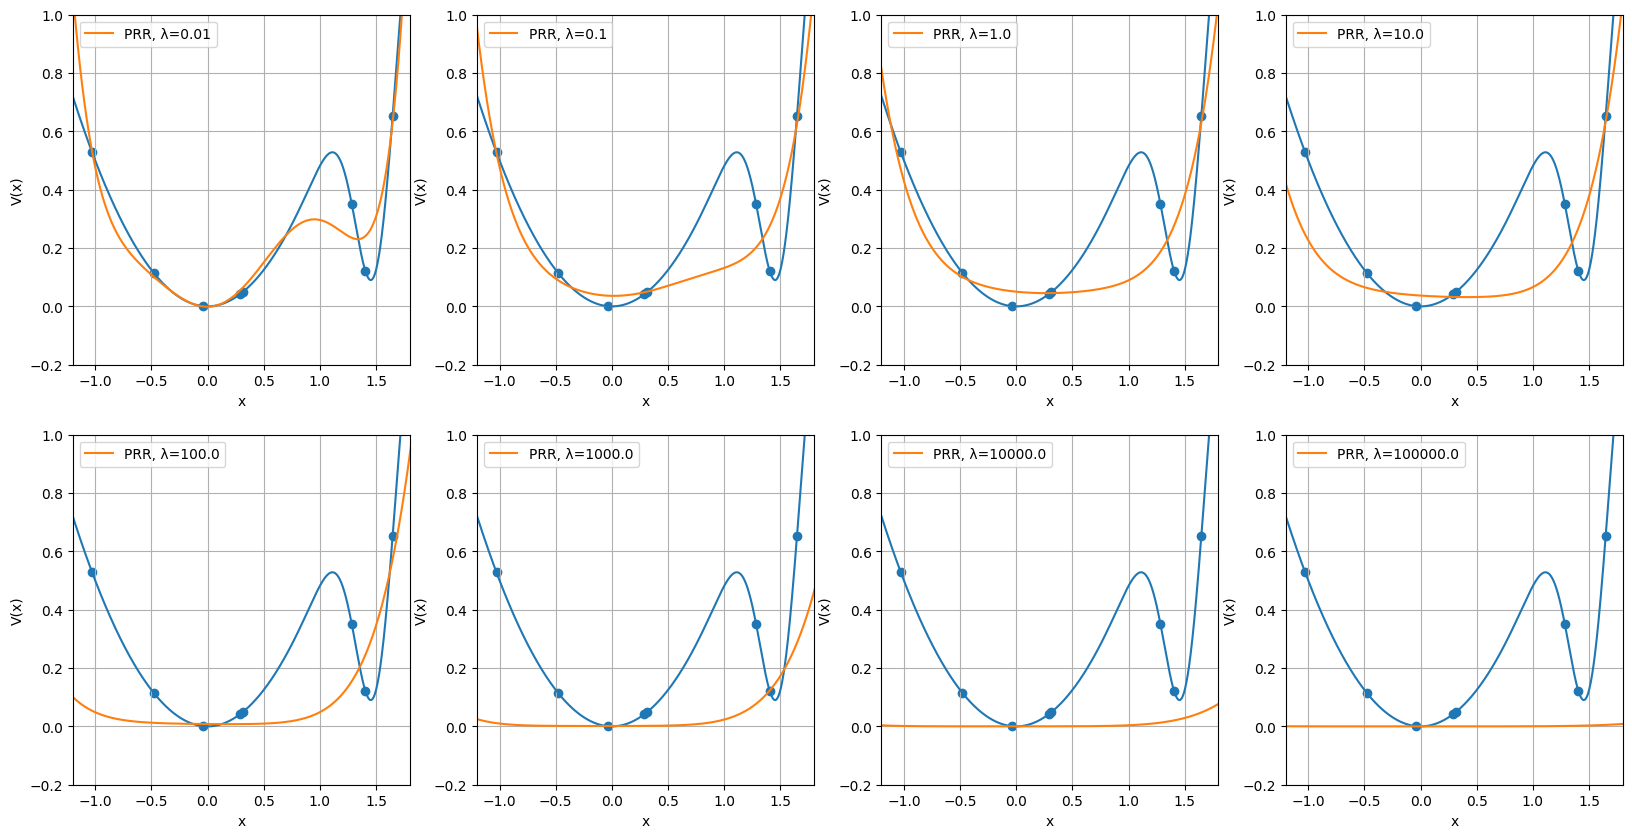

In [44]:
ls = 10**np.array([-2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0])

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for l, ax in zip(ls, axes):
    prr = PolyRidgeRegression(6, l)
    prr.fit(points, potential.V(points))

    ax.plot(x_lin, potential.V(x_lin))
    ax.scatter(points, potential.V(points))

    ax.plot(x_lin, prr.predict(x_lin), label=f'PRR, λ={l}')
    ax.grid()
    ax.set_xlabel('x')
    ax.set_ylabel('V(x)')

    ax.set_xlim(-1.2, 1.8)
    ax.set_ylim(-0.2, 1.0)
    ax.legend()

fig.savefig('w08b_l8.png')

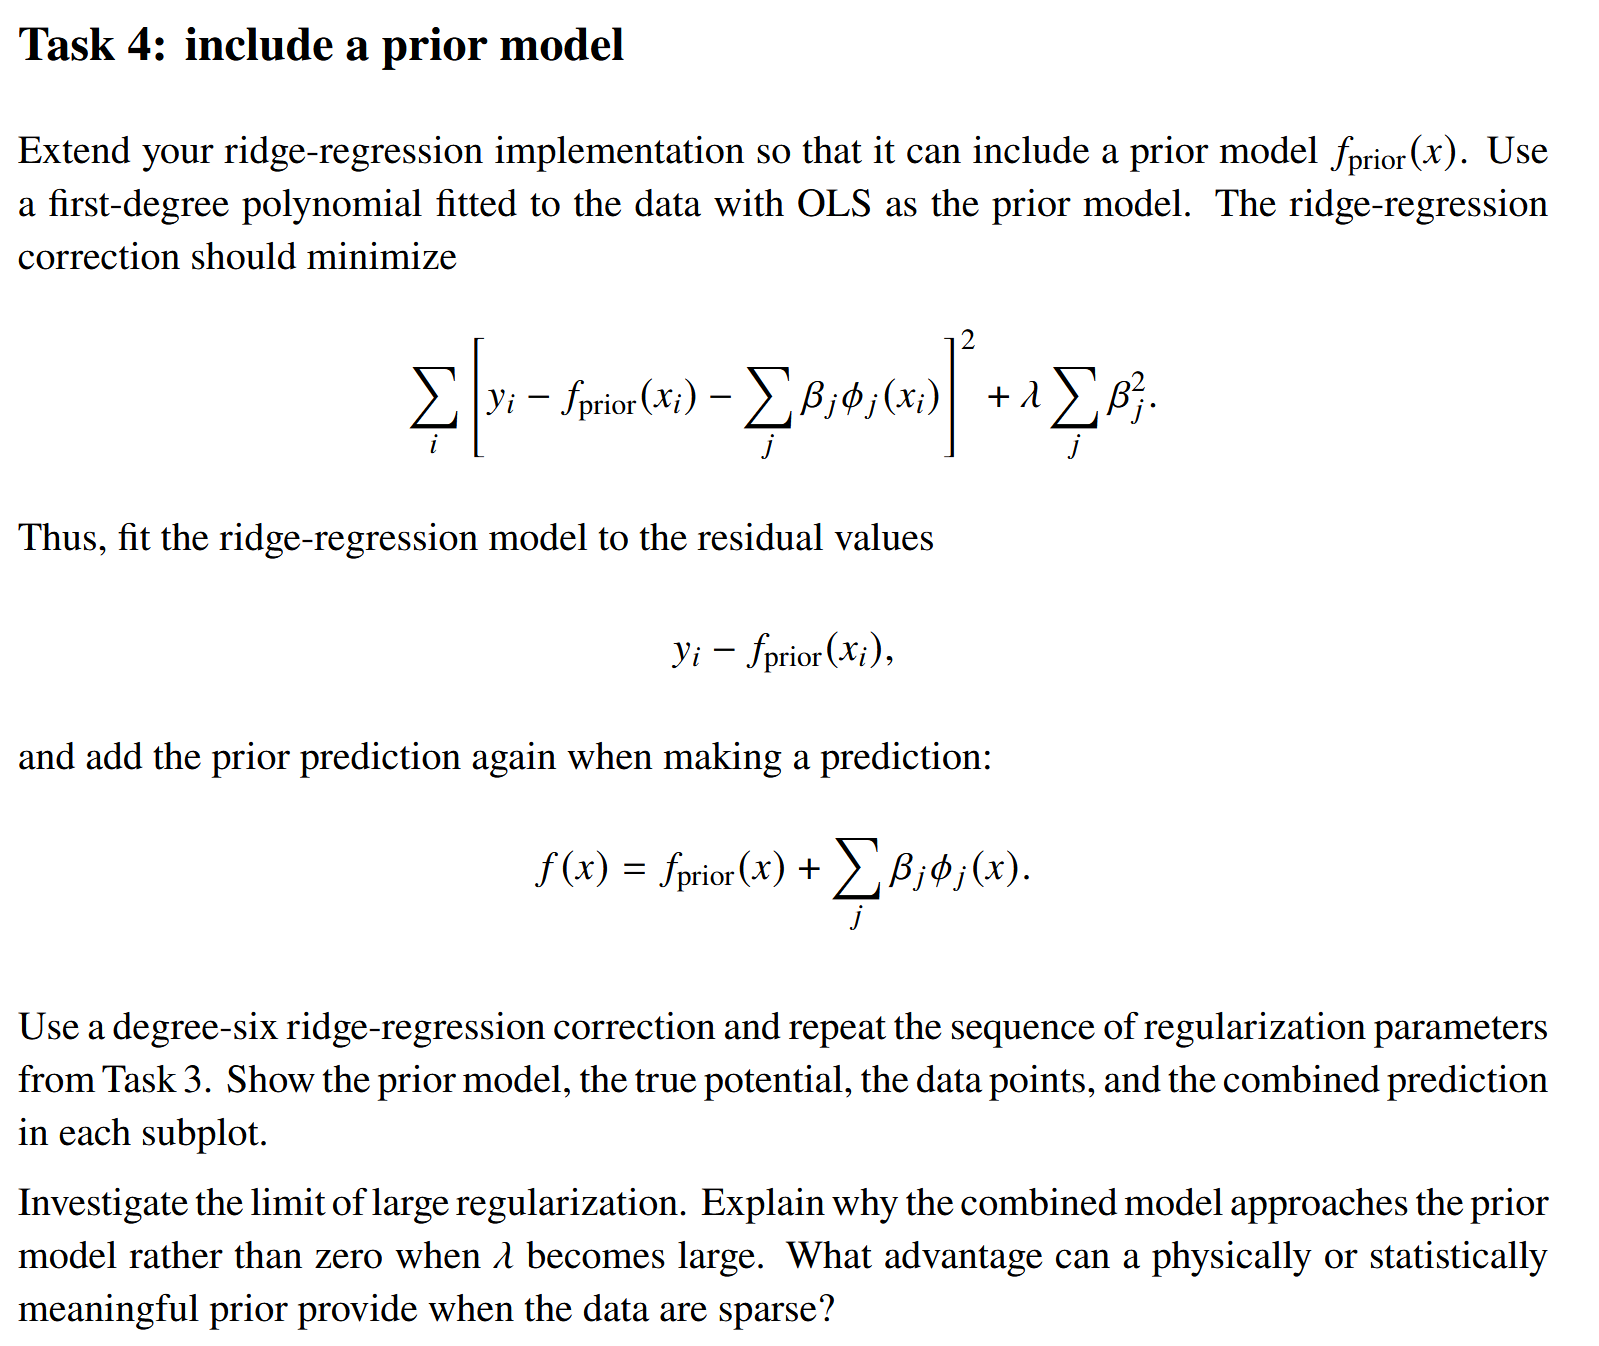

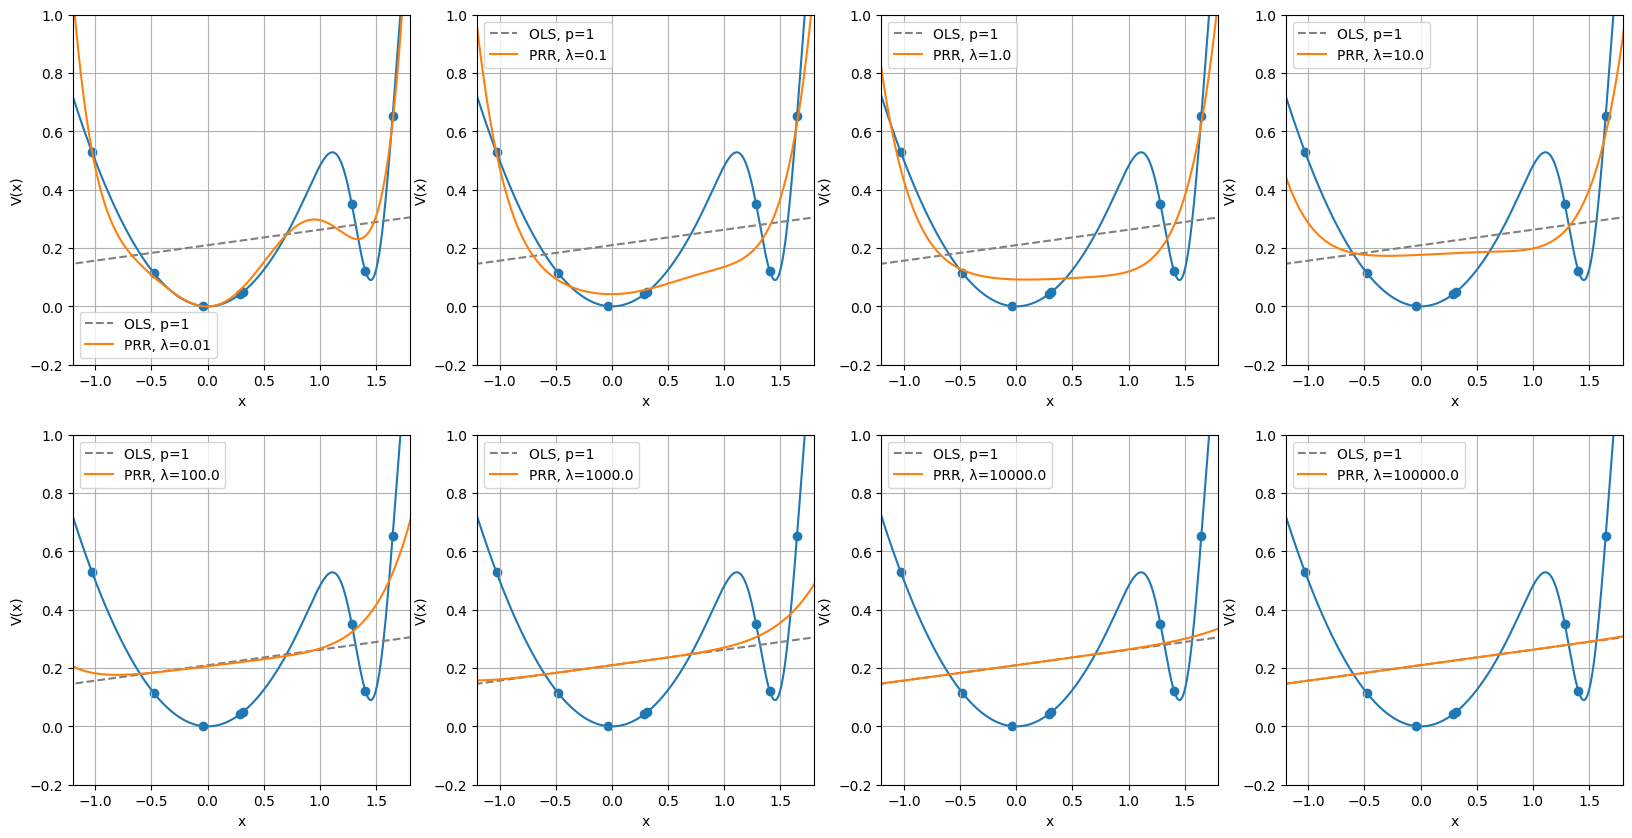

In [48]:
class PolyRidgeRegression:
    def __init__(self, Ndegree, lam, prior_model=None):
        self.Ndegree = Ndegree
        self.l = lam
        self.prior_model = prior_model
        self.beta = None

    def fit(self, X, y):
        X_aug = np.array([[x**p for p in range(self.Ndegree + 1)] for x in X])
        Il = self.l * np.identity(self.Ndegree + 1)
        Xs = np.linalg.inv((X_aug.T @ X_aug) + Il) @ X_aug.T
        
        # If a prior model is provided, fit to the residuals
        if self.prior_model is not None:
            # Assumes prior_model is a callable function or object with a predict method
            y_prior = self.prior_model.predict(X)
            y_target = y - y_prior
        else:
            y_target = y
            
        self.beta = Xs @ y_target
        return self.beta, X_aug

    def predict(self, X):
        if type(self.beta) == type(None):
            raise ValueError('No β, run .fit() first')
        
        X_aug = np.array([[x**p for p in range(self.Ndegree + 1)] for x in X])
        y_pred = X_aug @ self.beta
        
        # Add the prior prediction back when making a prediction
        if self.prior_model is not None:
            y_prior = self.prior_model.predict(X)
            y_pred = y_pred + y_prior
            
        return y_pred

    def plot(self, ax, X): 
        y = self.predict(X)
        ax.scatter(X, y)


fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
ols = OLFitPoly(1)
ols.fit(points, potential.V(points))

for l, ax in zip(ls, axes):
    prr = PolyRidgeRegression(6, l, prior_model=ols)
    prr.fit(points, potential.V(points))

    ax.plot(x_lin, potential.V(x_lin))
    ax.scatter(points, potential.V(points))

    ax.plot(x_lin, ols.predict(x_lin), '--', label='OLS, p=1', color='gray')
    ax.plot(x_lin, prr.predict(x_lin), label=f'PRR, λ={l}')
    ax.grid()
    ax.set_xlabel('x')
    ax.set_ylabel('V(x)')

    ax.set_xlim(-1.2, 1.8)
    ax.set_ylim(-0.2, 1.0)
    ax.legend()

### Explain why the combined model approaches the prior model rather than zero when $\lambda$ becomes large. 
In standard ridge regression, a very large regularization parameter ($\lambda \to \infty$) heavily penalizes the weights ($\beta$), shrinking them toward zero. Consequently, a standard model's predictions also shrink to zero. However, in this extended model, the ridge regression is only fitting the *residuals*. As $\lambda$ becomes large, the weights $\beta_j$ still shrink to zero, which means the ridge correction term ($\sum_j \beta_j \phi_j(x)$) becomes zero. Since the final prediction is the prior model plus the correction term, the combined model defaults entirely to the prior model ($f_{\text{prior}}(x) + 0$).

### What advantage can a physically or statistically meaningful prior provide when the data are sparse?
When data points are sparse, a highly flexible polynomial model is prone to wild oscillations or overfitting in the "gaps" between data points. A meaningful prior acts as an anchor. It provides a sensible, structurally sound baseline guess for the overall trend of the data. The ridge regression then only needs to learn minor, local corrections where the sparse data slightly deviates from the prior, resulting in much more robust and stable predictions across the entire domain.